**1.Importing Libraries**

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score,mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

warnings.filterwarnings('ignore')

**2. Importing Dataset**

In [19]:
df = pd.read_csv('Data/Position_Salaries.csv')
print(df)

            Position  Level   Salary
0   Business Analyst      1    45000
1  Junior Consultant      2    50000
2  Senior Consultant      3    60000
3            Manager      4    80000
4    Country Manager      5   110000
5     Region Manager      6   150000
6            Partner      7   200000
7     Senior Partner      8   300000
8            C-level      9   500000
9                CEO     10  1000000


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Position  10 non-null     object
 1   Level     10 non-null     int64 
 2   Salary    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes


**3. Data Preparation**

In [21]:
X = df.iloc[:, 1:2].values
y = df.iloc[:,2].values

**4. Random Forest Regressor Model**

In [22]:
label_encoder = LabelEncoder()
x_categorical = df.select_dtypes(include=['object']).apply(label_encoder.fit_transform)
x_numerical = df.select_dtypes(exclude=['object']).values
x = pd.concat([pd.DataFrame(x_numerical), x_categorical], axis=1).values
regressor =  RandomForestRegressor(n_estimators=10, random_state=0, oob_score=True)
regressor.fit(X,y)

RandomForestRegressor(n_estimators=10, oob_score=True, random_state=0)

**5. Making predictions and Evaluating**

In [30]:
oob_score = regressor.oob_score_
print(f'Out-Of-Bag score:{oob_score}')

prediction = regressor.predict(x)

mse = mean_squared_error(y,prediction)
print(f'Mean Squared Error:{mse}')

r2 = r2_score(y, predictions)
print(f'R-squared: {r2}')

Out-Of-Bag score:0.6819214296245728


ValueError: X has 3 features, but RandomForestRegressor is expecting 1 features as input.

**6. Visualizing**

ValueError: X has 3 features, but RandomForestRegressor is expecting 1 features as input.

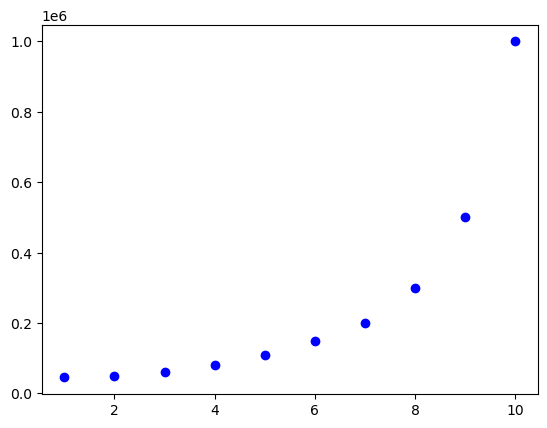

In [33]:
X_grid = np.arange(min(X[:, 0]), max(X[:, 0]), 0.01)  # Only the first feature
X_grid = X_grid.reshape(-1, 1)
X_grid = np.hstack((X_grid, np.zeros((X_grid.shape[0], 2))))  # Pad with zeros

plt.scatter(X[:, 0], y, color='blue', label="Actual Data")
plt.plot(X_grid[:, 0], regressor.predict(X_grid), color='green', label="Random Forest Prediction")  
plt.title("Random Forest Regression Results")
plt.xlabel('Position Level')
plt.ylabel('Salary')
plt.legend()
plt.show()

**7. Visualizing a Single Decision Tree from the Random Forest Model**

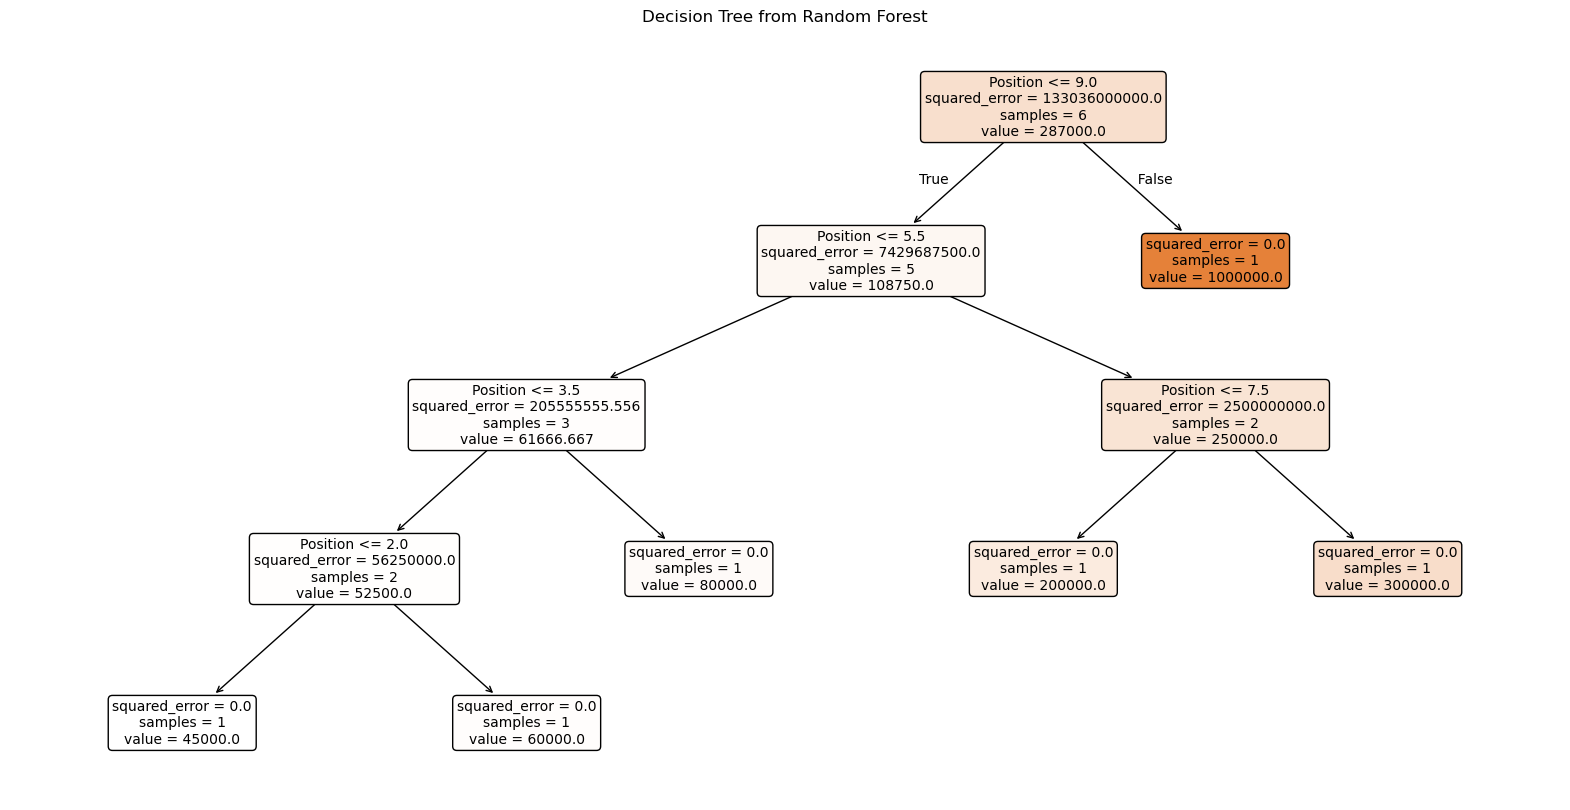

In [34]:
from sklearn.tree import plot_tree
tree_to_plot = regressor.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(tree_to_plot, feature_names=df.columns.tolist(), filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree from Random Forest")
plt.show()